# XAU/USD three-year structures

Prices a forward strip, a collar strip, and a seagull on the `close` rates label
written by `xau_usd_rates.ipynb`. Run that notebook first. Opening the name
without a datetime uses the newest instance.

The bank faces a producer. On each date it buys a forward, or it sells a put
and buys a call. The seagull also buys a put 150 dollars below the sold put.
Settlements are the 16th of each month, moved with modified following, from
October 2026 through September 2029. Twelve dates share a strike. The next
twelve are one step higher, and the last twelve are one step higher again.

The solve moves the year-1 strike until the bank's present value equals
`target_pv`. A positive target is value the producer gives the bank.


WARNING sjd._core: Anchor has no observation; values are flat through the first observation
INFO sjd.markets.rates: loaded market XAU/USD label close at 2026-09-16T16:00:00 anchor 2026-09-16 roll DETERMINISTIC


label close at 2026-09-16T16:00:00  anchor 2026-09-16  2026-10-16 outright 2,407.85
forward year-1 strike 2,417.3223  present value 250,000.00
collar  year-1 strike 2,360.5015  present value 250,000.00
seagull year-1 put    2,499.0658  present value 250,000.00
 group  forward_pv  collar_pv  seagull_pv
     1   32,414.60  33,016.82  -24,844.44
     2   86,378.38  85,759.75   91,655.68
     3  131,207.02 131,223.43  183,188.76


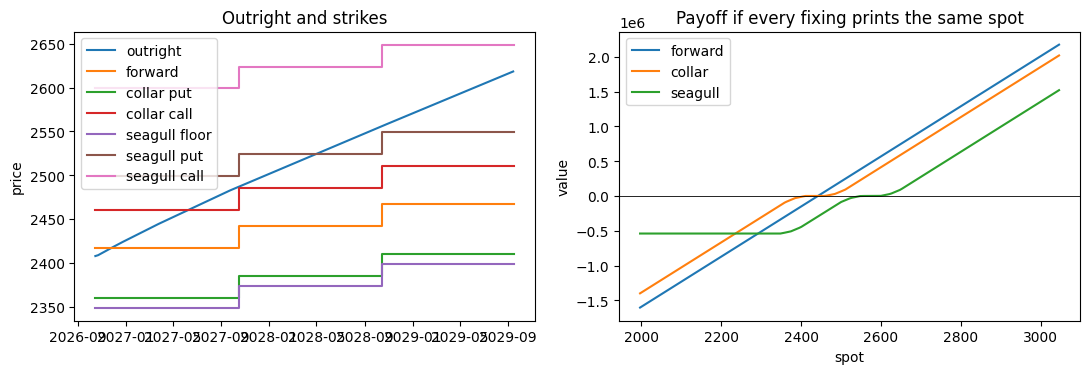

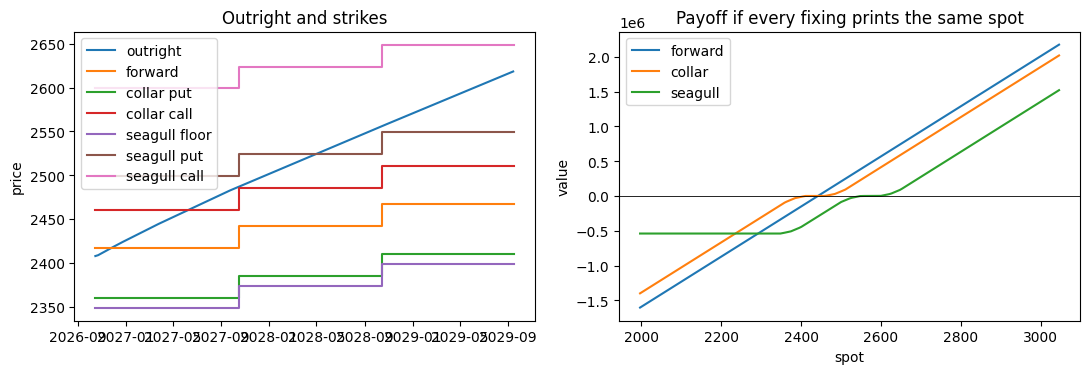

In [1]:
import logging
from datetime import date
from pathlib import Path

import sjd
from sjd import markets
from sjd.structuring import (
    CollarStrip,
    ForwardStrip,
    SeagullStrip,
    compare_structures,
    plot_structures,
    solve_pv,
    step_ladder,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
sjd.set_log_level("INFO", dedupe_warnings=True)

volume = 100.0
yearly_step = 25.0
collar_width = 100.0
floor_gap = 150.0
target_pv = 250_000.0

rates_path = Path(sjd.markets.__file__).resolve().parents[2] / "notebooks" / "local" / "xau_usd.db"
loaded = markets.open_market(rates_path, "XAU", "USD", label="close")
assert loaded.label.name == "close"
schedule = loaded.monthly_schedule(date(2026, 10, 16), 36)
assert len(schedule) == 36
assert schedule.periods[0].settlement == date(2026, 10, 16)
print(
    f"label {loaded.label.name} at {loaded.label.as_of_text}  anchor {loaded.anchor}  "
    f"{schedule.periods[0].settlement} outright "
    f"{loaded.forward.get_forward(schedule.periods[0].settlement):,.2f}"
)


def ladder(start):
    return step_ladder(start, yearly_step, len(schedule))


def forwards(start):
    return ForwardStrip.build(schedule, ladder(start), volume)


def collars(start):
    return CollarStrip.build(schedule, ladder(start), width=collar_width, volume=volume)


def seagulls(start):
    puts = ladder(start)
    return SeagullStrip.build(
        schedule,
        [strike - floor_gap for strike in puts],
        puts,
        [strike + collar_width for strike in puts],
        volume,
    )


forward = solve_pv(forwards, loaded, target_pv=target_pv)
collar = solve_pv(collars, loaded, target_pv=target_pv)
seagull = solve_pv(seagulls, loaded, target_pv=target_pv, bracket=(200.0, 10_000.0))
assert abs(forward.parameter - 2_417.3223) < 5e-4
assert abs(collar.parameter - 2_360.5015) < 5e-4
assert abs(forward.pv - target_pv) < 0.01
assert abs(collar.pv - target_pv) < 0.01
assert abs(seagull.pv - target_pv) < 0.01
print(f"forward year-1 strike {forward.parameter:,.4f}  present value {forward.pv:,.2f}")
print(f"collar  year-1 strike {collar.parameter:,.4f}  present value {collar.pv:,.2f}")
print(f"seagull year-1 put    {seagull.parameter:,.4f}  present value {seagull.pv:,.2f}")

summary, table = compare_structures(
    {
        "forward": forward.structure,
        "collar": collar.structure,
        "seagull": seagull.structure,
    },
    loaded,
)
print(summary.to_string(index=False, float_format=lambda value: f"{value:,.2f}"))
plot_structures(
    {
        "forward": forward.structure,
        "collar": collar.structure,
        "seagull": seagull.structure,
    },
    loaded,
)
